# Little Lemon Analysis and Sales Report

## 1. Project introduction

Analyze a restaurant's sales using MySQL Connector/Python and a two-connection pool. This project uses the separate `little_lemon_sales` database. It never modifies the existing Django application or its tables.

**Every customer, employee, booking, and sale here is fictional demonstration data. No official course sales dataset was supplied or found in the capstone.** Five sample menu names and prices come from that project's seed command. Amounts are USD; dates and booking procedures use UTC. Run all cells in order from this folder.

## 2. Import Python libraries

These imports provide pooled MySQL access, safe transactions, report queries, and notebook display. The implementation is included in `src/`; SQL definitions are included in `sql/`.

In [1]:
from pathlib import Path
from datetime import timedelta
from contextlib import ExitStack
import json
import secrets
import mysql.connector
from mysql.connector import Error
from mysql.connector.pooling import MySQLConnectionPool
from IPython.display import SVG, display
from src.connection_pool import ROOT, create_pool, load_config, pooled_cursor
from src.database import initialize_database, seed_database, validate_data
from src.procedures import create_procedures, call_procedure, PROCEDURES
from src.reports import REPORT_QUERIES, run_report, print_table, write_report
print("MySQL Connector/Python version:", mysql.connector.__version__)

MySQL Connector/Python version: 26.10.0


## 3. Configure MySQL connection

Read the private environment file. Credentials are never printed or stored in this notebook. The configuration rejects any database name other than `little_lemon_sales`.

In [2]:
dbconfig = load_config()
print("Configured database:", dbconfig["database"])
print("Credentials loaded privately from environment variables.")

Configured database: little_lemon_sales
Credentials loaded privately from environment variables.


## 4. Create MySQL connection pool

`create_pool` uses `MySQLConnectionPool(pool_name='pool_a', pool_size=2)`. It initially omits a default database so the next section can create a missing sales database through a pooled connection. Every later checkout explicitly selects the sales schema.

In [3]:
pool = create_pool(dbconfig)
assert isinstance(pool, MySQLConnectionPool)
assert pool.pool_name == "pool_a" and pool.pool_size == 2

Connecting to MySQL database...
Creating connection pool...
Connection established successfully.
The connection pool is created with a name: pool_a
The pool size is: 2


## 5. Create database and tables

Create the dedicated database and seven tables with `IF NOT EXISTS`. Foreign keys protect relationships; a composite foreign key makes each order's customer and table match its booking. MySQL DDL commits implicitly: schema creation is non-destructive and resumable, but not an atomic transaction.

In [4]:
initialize_database(pool)
with pooled_cursor(pool) as (connection, cursor):
    cursor.execute("SELECT DATABASE(), VERSION()")
    database_name, server_version = cursor.fetchone()
    print("Database connection established:", database_name)
    print("MySQL server version:", server_version)
    cursor.execute("SHOW TABLES")
    for row in cursor.fetchall():
        print("Created table:", row[0])

Connection acquired from pool.
Closing cursor...
Returning connection to pool...
Connection acquired from pool.


Records committed successfully.
Closing cursor...
Returning connection to pool...
Database tables created successfully.
Connection acquired from pool.
Database connection established: little_lemon_sales
MySQL server version: 8.4.13
Created table: Bookings
Created table: Customers
Created table: Employees
Created table: MenuItems
Created table: OrderDeliveryStatus
Created table: OrderItems
Created table: Orders
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...


## 6. Insert sample records

The seed uses deterministic IDs and inserts only missing IDs. It never replaces existing records. All seed inserts share one transaction and commit only after the whole script succeeds.

In [5]:
seed_database(pool)

Inserting restaurant demonstration data...
Connection acquired from pool.


Records committed successfully.
Closing cursor...
Returning connection to pool...
Demonstration records inserted; existing identifiers were preserved.


## 7. Validate inserted records

Count every table, reconcile stored order totals with quantity × historical unit price, and check relationships. A mismatch raises an exception instead of reporting success.

In [6]:
validation = validate_data(pool)
baseline_counts = dict(validation["row_counts"])
for table, count in baseline_counts.items():
    print(f"{table}: {count} records")

Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Inserted records validated: {'Customers': 8, 'Employees': 4, 'MenuItems': 10, 'Bookings': 12, 'Orders': 12, 'OrderItems': 36, 'OrderDeliveryStatus': 12}
Order totals match their line items; foreign-key violations: 0
Customers: 8 records
Employees: 4 records
MenuItems: 10 records
Bookings: 12 records
Orders: 12 records
OrderItems: 36 records
OrderDeliveryStatus: 12 records


## 8. Create stored procedures

Create the eight required procedures. Existing definitions are preserved by `CREATE PROCEDURE IF NOT EXISTS`. Booking changes remain uncommitted until Python explicitly commits them. Procedures reject duplicates, invalid times, unknown customers, and changes to bookings linked to sales history.

In [7]:
create_procedures(pool)
with pooled_cursor(pool) as (connection, cursor):
    cursor.execute("SELECT ROUTINE_NAME FROM information_schema.ROUTINES WHERE ROUTINE_SCHEMA = DATABASE() ORDER BY ROUTINE_NAME")
    available = {row[0] for row in cursor.fetchall()}
    assert set(PROCEDURES).issubset(available)
    for name in sorted(available):
        print("Stored procedure available:", name)

Connection acquired from pool.


Records committed successfully.
Closing cursor...
Returning connection to pool...
Stored procedures created successfully; existing definitions preserved.
Connection acquired from pool.
Stored procedure available: CancelBooking
Stored procedure available: GetCustomerOrders
Stored procedure available: GetEmployeeBookings
Stored procedure available: GetMaxQuantity
Stored procedure available: GetPopularMenuItems
Stored procedure available: GetSalesReport
Stored procedure available: ManageBooking
Stored procedure available: UpdateBooking
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...


## 9. Execute stored procedures

Run all eight procedures. Read-only calls return actual results. The three management procedures use one temporary future booking; it is removed after the demonstration. No seeded booking is updated or deleted.

In [8]:
for name, args in [
    ("GetMaxQuantity", ()), ("GetSalesReport", ()),
    ("GetCustomerOrders", (1001,)), ("GetPopularMenuItems", ()),
    ("GetEmployeeBookings", ()),
]:
    call_procedure(pool, name, args)

# Reserve an unused identifier and future slot for our own temporary record.
demo_id = 900_000_000 + secrets.randbelow(100_000_000)
with pooled_cursor(pool) as (connection, cursor):
    cursor.execute("SELECT CURRENT_DATE()")
    demo_day = cursor.fetchone()[0] + timedelta(days=365)
    cursor.execute("SELECT COUNT(*) FROM Bookings WHERE BookingID=%s", (demo_id,))
    assert cursor.fetchone()[0] == 0, "Random ID collision; rerun this cell."
    while True:
        cursor.execute("SELECT COUNT(*) FROM Bookings WHERE TableNo=50 AND ((BookingDate=%s AND BookingSlot='19:00:00') OR (BookingDate=%s AND BookingSlot='20:00:00'))", (demo_day, demo_day + timedelta(days=1)))
        if cursor.fetchone()[0] == 0:
            break
        demo_day += timedelta(days=1)
created = False
try:
    call_procedure(pool, "ManageBooking", (demo_id, demo_day, "19:00:00", 50, 1001, 2001), commit=True)
    created = True
    call_procedure(pool, "UpdateBooking", (demo_id, demo_day + timedelta(days=1), "20:00:00"), commit=True)
    call_procedure(pool, "CancelBooking", (demo_id,), commit=True)
    created = False
finally:
    if created:
        call_procedure(pool, "CancelBooking", (demo_id,), commit=True)
print("All eight stored procedures executed. Temporary booking removed.")

Executing procedure: GetMaxQuantity
Connection acquired from pool.
(6,)
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Executing procedure: GetSalesReport
Connection acquired from pool.
(12, Decimal('835.00'), Decimal('69.58'), Decimal('112.50'), Decimal('31.00'))
Closing cursor...
Uncommitted transaction rolled back.


Returning connection to pool...
Executing procedure: GetCustomerOrders
Connection acquired from pool.
(1001, 'Maya Bennett', 5001, datetime.date(2026, 1, 15), 4001, 1, Decimal('73.00'))
(1001, 'Maya Bennett', 5005, datetime.date(2026, 3, 15), 4005, 1, Decimal('60.00'))
(1001, 'Maya Bennett', 5012, datetime.date(2026, 6, 15), 4012, 2, Decimal('112.50'))
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Executing procedure: GetPopularMenuItems
Connection acquired from pool.
(3006, 'Sparkling water', 'Beverages', Decimal('17'), Decimal('51.00'))
(3007, 'Lemonade', 'Beverages', Decimal('12'), Decimal('54.00'))
(3003, 'Lemon chicken', 'Mains', Decimal('11'), Decimal('214.50'))
(3005, 'Lemon dessert', 'Desserts', Decimal('9'), Decimal('67.50'))
(3001, 'Greek salad', 'Starters', Decimal('8'), Decimal('100.00'))
(3008, 'Espresso', 'Beverages', Decimal('8'), Decimal('28.00'))
(3002, 'Bruschetta', 'Starters', Decimal('7'), Decimal('56.00'))
(3009, 'Grilled se

Records committed successfully.
Closing cursor...
Returning connection to pool...
All eight stored procedures executed. Temporary booking removed.


## 10. Retrieve query results

This cell shows the assignment's `callproc` and `stored_results` workflow directly. Each result cursor is closed after it is read. Connector/Python 26.10 marks `stored_results` deprecated; it is retained here because the assignment explicitly requests it and is verified with the pinned connector version.

In [9]:
print("Executing sales report procedure...")
with pooled_cursor(pool) as (connection, cursor):
    cursor.callproc("GetSalesReport", ())
    for result in cursor.stored_results():
        try:
            for row in result.fetchall():
                print(row)
        finally:
            result.close()

Executing sales report procedure...


Connection acquired from pool.
(12, Decimal('835.00'), Decimal('69.58'), Decimal('112.50'), Decimal('31.00'))
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...


/tmp/ipykernel_194848/1261384381.py:4: DeprecationWarning: Call to deprecated function stored_results. Reason: The property counterpart 'stored_results' will be added in a future release, and this method will be removed.
  for result in cursor.stored_results():


## 11. Perform sales analysis

Use JOINs, aggregate functions, GROUP BY, HAVING, subqueries, and window functions. The least-popular list includes unsold menu items; monthly growth compares recorded months only.

In [10]:
analysis = {}
for report_name in REPORT_QUERIES:
    rows = run_report(pool, report_name)
    analysis[report_name] = rows
    print_table(report_name.replace("_", " ").title(), rows)

Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...

Summary
TotalOrders | TotalSales | AverageOrderValue | HighestOrderValue | LowestOrderValue
------------+------------+-------------------+-------------------+-----------------
12          | 835.00     | 69.58             | 112.50            | 31.00           
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...

Category Sales
Type      | QuantitySold | TotalSales
----------+--------------+-----------
Mains     | 24           | 478.50    
Starters  | 15           | 156.00    
Beverages | 37           | 133.00    
Desserts  | 9            | 67.50     
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...

Popular Items
ItemID | ItemName         | Type      | QuantitySold | ItemSales
-------+------------------+-----------+--------------+-------

## 12. Produce restaurant sales report

Generate `REPORT.md`, a machine-readable JSON report, and a labeled monthly-sales chart from those actual SQL results. These are gross recorded order values, not restaurant profit.

Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...


Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.


Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.


Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...


Restaurant sales report saved to REPORT.md and output/.

Restaurant sales summary (demonstration data, USD)
TotalOrders | TotalSales | AverageOrderValue | HighestOrderValue | LowestOrderValue
------------+------------+-------------------+-------------------+-----------------
12          | 835.00     | 69.58             | 112.50            | 31.00           


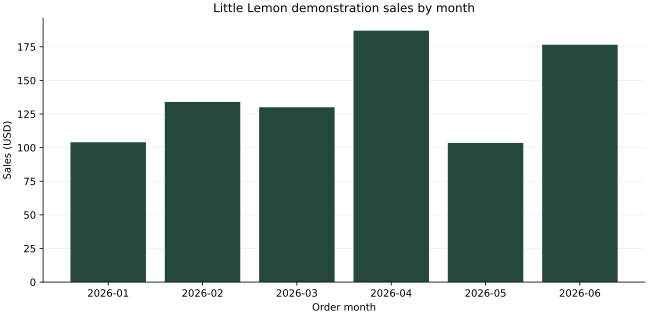

In [11]:
reports = write_report(pool)
print_table("Restaurant sales summary (demonstration data, USD)", reports["summary"])
display(SVG(filename=str(ROOT / "output" / "monthly_sales.svg")))

## 13. Demonstrate transaction commits

Create another temporary booking, explicitly commit it, and verify it from a different pooled connection. Then make an uncommitted change and roll it back. The final cleanup cancels only this demonstration's booking.

In [12]:
transaction_id = 1_100_000_000 + secrets.randbelow(100_000_000)
transaction_day = demo_day + timedelta(days=100)
with pooled_cursor(pool) as (connection, cursor):
    cursor.execute("SELECT COUNT(*) FROM Bookings WHERE BookingID=%s", (transaction_id,))
    assert cursor.fetchone()[0] == 0, "Random ID collision; rerun this cell."
    while True:
        cursor.execute("SELECT COUNT(*) FROM Bookings WHERE BookingDate=%s AND BookingSlot='18:00:00' AND TableNo=49", (transaction_day,))
        if cursor.fetchone()[0] == 0:
            break
        transaction_day += timedelta(days=1)
committed = False
try:
    with pooled_cursor(pool) as (connection, cursor):
        cursor.callproc("ManageBooking", (transaction_id, transaction_day, "18:00:00", 49, 1001, 2001))
        for result in cursor.stored_results():
            try:
                for row in result.fetchall():
                    print(row)
            finally:
                result.close()
        connection.commit()
        committed = True
        print("Records committed successfully.")
    with pooled_cursor(pool) as (connection, cursor):
        cursor.execute("SELECT COUNT(*) FROM Bookings WHERE BookingID=%s", (transaction_id,))
        assert cursor.fetchone()[0] == 1
        print("A second pooled connection confirms the committed booking exists.")
    with pooled_cursor(pool) as (connection, cursor):
        cursor.execute("UPDATE Bookings SET BookingSlot='17:00:00' WHERE BookingID=%s", (transaction_id,))
        connection.rollback()
        print("Uncommitted update rolled back.")
    with pooled_cursor(pool) as (connection, cursor):
        cursor.execute("SELECT BookingSlot FROM Bookings WHERE BookingID=%s", (transaction_id,))
        assert str(cursor.fetchone()[0]) == "18:00:00"
        print("Original time preserved after rollback.")
finally:
    if committed:
        call_procedure(pool, "CancelBooking", (transaction_id,), commit=True)

Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
(1160402278, 'Booking created; commit required')
Records committed successfully.
Closing cursor...
Returning connection to pool...
Connection acquired from pool.
A second pooled connection confirms the committed booking exists.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Uncommitted update rolled back.
Closing cursor...
Returning connection to pool...
Connection acquired from pool.
Original time preserved after rollback.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Executing procedure: CancelBooking
Connection acquired from pool.
(1160402278, 'Booking cancelled; commit required')
Records committed successfully.
Closing cursor...
Returning connection to pool...


/tmp/ipykernel_194848/1711525922.py:15: DeprecationWarning: Call to deprecated function stored_results. Reason: The property counterpart 'stored_results' will be added in a future release, and this method will be removed.
  for result in cursor.stored_results():


## 14. Demonstrate connection cleanup

Trigger a deliberate, handled SQL error. The context manager still closes the cursor and returns the connection. Acquiring both pool slots afterwards proves the error did not leave a connection checked out. Returning a pooled connection keeps its physical socket ready for reuse; the kernel/process owns the pool lifetime.

In [13]:
try:
    with pooled_cursor(pool) as (connection, cursor):
        cursor.execute("SELECT DeliberatelyMissingColumn FROM Customers")
except Error as er:
    print("Expected demonstration error handled.")
    print("Error code:", er.errno)
    print("Error message:", er.msg)
with ExitStack() as stack:
    for slot in range(pool.pool_size):
        connection, cursor = stack.enter_context(pooled_cursor(pool))
        cursor.execute("SELECT 1")
        assert cursor.fetchone()[0] == 1
        print("Pool slot available after error:", slot + 1)
print("All acquired connections returned to pool.")

Connection acquired from pool.
Error code: 1054
Error message: Unknown column 'DeliberatelyMissingColumn' in 'field list'
Closing cursor...
Returning connection to pool...
Expected demonstration error handled.
Error code: 1054
Error message: Unknown column 'DeliberatelyMissingColumn' in 'field list'
Connection acquired from pool.
Pool slot available after error: 1
Connection acquired from pool.
Pool slot available after error: 2
Closing cursor...
Returning connection to pool...
Closing cursor...
Returning connection to pool...
All acquired connections returned to pool.


## 15. Display final results

Validate the data again after all temporary transactions and confirm that rerunning initialization and seeding does not create duplicates or change the demo sales.

In [14]:
initialize_database(pool)
seed_database(pool)
final_validation = validate_data(pool)
assert final_validation["row_counts"] == baseline_counts
final_summary = run_report(pool, "summary")
print_table("Final restaurant sales results (demonstration data, USD)", final_summary)
print("Rerun preserved row counts:", final_validation["row_counts"])
print("Pool name:", pool.pool_name)
print("Pool size:", pool.pool_size)
print("Notebook execution completed successfully.")

Connection acquired from pool.
Closing cursor...
Returning connection to pool...
Connection acquired from pool.


Records committed successfully.
Closing cursor...
Returning connection to pool...
Database tables created successfully.
Inserting restaurant demonstration data...
Connection acquired from pool.


Records committed successfully.
Closing cursor...
Returning connection to pool...
Demonstration records inserted; existing identifiers were preserved.
Connection acquired from pool.


Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Inserted records validated: {'Customers': 8, 'Employees': 4, 'MenuItems': 10, 'Bookings': 12, 'Orders': 12, 'OrderItems': 36, 'OrderDeliveryStatus': 12}
Order totals match their line items; foreign-key violations: 0
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...

Final restaurant sales results (demonstration data, USD)
TotalOrders | TotalSales | AverageOrderValue | HighestOrderValue | LowestOrderValue
------------+------------+-------------------+-------------------+-----------------
12          | 835.00     | 69.58             | 112.50            | 31.00           
Rerun preserved row counts: {'Customers': 8, 'Employees': 4, 'MenuItems': 10, 'Bookings': 12, 'Orders': 12, 'OrderItems': 36, 'OrderDeliveryStatus': 12}
Pool name: pool_a
Pool size: 2
Notebook execution completed successfully.


## 16. Conclusion

The executed output demonstrates a real MySQL connection pool, database creation, committed sample records, stored procedures, validated sales calculations, and connection cleanup. All data is synthetic, so the totals describe this sample only. Missing costs, tax, refunds, and a complete trading calendar prevent profit or real-business conclusions. Existing identifiers and routines are preserved on rerun; deliberate changes to their definitions require a separately reviewed migration. The original Django checkout and database remain separate.

See `REPORT.md`, `COURSERA_RUBRIC_CHECKLIST.md`, and `evidence/verification.json` for the report and recorded validation. This notebook does not claim to reproduce an unavailable official course dataset.